# Section 1 - Business Understanding

## Client
The client is a logistics and delivery operations organization managing shipments across warehouses, routes, shipping modes, and delivery partners.

## Business problem
The organization needs a consistent view of delivery performance, operational delays, warehouse processing, partner performance, and logistics costs. Raw shipment records must be cleaned and transformed into reliable measures for decision-making.

## Objectives
- Measure delivery volume, delivery status, on-time performance, and delays.
- Identify routes, warehouses, shipping modes, and partners that require attention.
- Understand shipping, fuel, and total logistics cost drivers.
- Produce evidence-based business insights and recommendations.

## Business questions
- How many orders are delivered, delayed, and on time?
- Which routes and warehouses have the highest delay or processing burden?
- Which shipping modes and delivery partners provide the best balance of service and cost?
- What are the major logistics cost patterns?
- What actions can improve delivery performance and cost efficiency?

In [1]:
# Section 2 - Import Libraries
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Make the project source package available from either notebook or project-root execution.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_data
from src.data_cleaner import (
    clean_data,
    handle_missing_values,
    remove_duplicates,
    clean_text_columns,
    clean_date_columns,
    validate_numeric_columns,
    validate_business_rules,
    create_derived_columns,
)
from src.business_analysis import *
from src.visualization import *

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

In [2]:
# Section 3 - Load Data
raw_path = project_root / "data" / "raw" / "logistics_data.csv"
raw_df = load_data(str(raw_path))
print(f"Loaded {len(raw_df):,} rows from {raw_path}")
raw_df.head()

Loaded 5,000 rows from c:\Users\HP 440 G8\OneDrive\Documents\python_nit\Logistics Delivery Performance & Cost Analytics\data\raw\logistics_data.csv


,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,shipping_mode,delivery_partner,shipping_cost,fuel_cost,warehouse_processing_hours,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag
0,ORD101253,CUST12780,2025-03-12,Bengaluru,Bengaluru,Chennai,451.70,Home & Kitchen,7,5.51,Road,DTDC,"2,044.56",381.66,8.36,2025-03-14,2025-03-19,2025-03-24,Delayed,3.00,No,No
1,ORD102838,CUST11842,2025-12-02,Delhi,Delhi,Surat,592.80,Automotive,1,1.05,Road,Delhivery,"2,582.70",385.02,10.33,2025-12-05,2025-12-12,2025-12-12,Delivered,4.00,No,No
2,ORD103457,CUST10940,2025-04-21,Pune,Pune,Nagpur,191.90,Clothing,3,9.09,Rail,Shadowfax,817.23,185.83,8.88,2025-04-23,2025-04-28,2025-04-28,Delivered,5.00,No,No
3,ORD100061,CUST10263,2025-02-21,Pune,Pune,Coimbatore,376.40,Clothing,7,1.34,Road,Blue Dart,"1,713.22",386.35,10.18,2025-02-24,2025-03-02,2025-03-04,Delayed,3.00,No,No
4,ORD103947,CUST12467,2025-08-22,Mumbai,Mumbai,Delhi,895.30,Sports,5,3.95,Road,XpressBees,"3,980.06",990.42,11.17,2025-08-24,2025-08-30,2025-08-30,Delivered,4.00,No,No


In [3]:
# Section 4 - Basic Data Understanding
print("Shape:", raw_df.shape)
print("\nHead:")
display(raw_df.head())
print("\nTail:")
display(raw_df.tail())
print("\nInfo:")
raw_df.info()
print("\nDescriptive statistics:")
display(raw_df.describe(include="all"))
print("\nColumns:")
print(raw_df.columns.tolist())
print("\nData types:")
display(raw_df.dtypes.rename("dtype").to_frame())

Shape: (5000, 22)

Head:


,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,shipping_mode,delivery_partner,shipping_cost,fuel_cost,warehouse_processing_hours,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag
0,ORD101253,CUST12780,2025-03-12,Bengaluru,Bengaluru,Chennai,451.70,Home & Kitchen,7,5.51,Road,DTDC,"2,044.56",381.66,8.36,2025-03-14,2025-03-19,2025-03-24,Delayed,3.00,No,No
1,ORD102838,CUST11842,2025-12-02,Delhi,Delhi,Surat,592.80,Automotive,1,1.05,Road,Delhivery,"2,582.70",385.02,10.33,2025-12-05,2025-12-12,2025-12-12,Delivered,4.00,No,No
2,ORD103457,CUST10940,2025-04-21,Pune,Pune,Nagpur,191.90,Clothing,3,9.09,Rail,Shadowfax,817.23,185.83,8.88,2025-04-23,2025-04-28,2025-04-28,Delivered,5.00,No,No
3,ORD100061,CUST10263,2025-02-21,Pune,Pune,Coimbatore,376.40,Clothing,7,1.34,Road,Blue Dart,"1,713.22",386.35,10.18,2025-02-24,2025-03-02,2025-03-04,Delayed,3.00,No,No
4,ORD103947,CUST12467,2025-08-22,Mumbai,Mumbai,Delhi,895.30,Sports,5,3.95,Road,XpressBees,"3,980.06",990.42,11.17,2025-08-24,2025-08-30,2025-08-30,Delivered,4.00,No,No



Tail:


,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,shipping_mode,delivery_partner,shipping_cost,fuel_cost,warehouse_processing_hours,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag
4995,ORD100976,CUST10660,2025-10-17,Delhi,Delhi,Bengaluru,150.00,Clothing,5,10.55,Road,Shadowfax,793.26,182.51,10.59,2025-10-20,2025-10-25,2025-10-25,Delivered,4.00,No,No
4996,ORD101985,CUST11721,2025-07-05,Mumbai,Mumbai,Pune,625.20,Home & Kitchen,7,3.17,Air,XpressBees,"5,781.16",663.26,12.09,2025-07-08,2025-07-11,2025-07-14,Delayed,4.00,No,No
4997,ORD101270,CUST11701,2025-07-23,Chennai,Chennai,Lucknow,409.20,Clothing,6,2.10,Road,Blue Dart,"1,899.21",465.21,4.70,2025-07-24,2025-07-30,2025-08-02,Delayed,4.00,Yes,No
4998,ORD104393,CUST10864,2025-03-08,Chennai,Chennai,Kolkata,158.00,Grocery,6,11.25,Road,Ecom Express,"1,016.99",94.64,6.91,2025-03-09,2025-03-14,2025-03-14,Delivered,4.00,No,No
4999,ORD101274,CUST10398,2025-07-03,Mumbai,Mumbai,Delhi,607.50,Home & Kitchen,4,7.85,Rail,Blue Dart,"2,043.30",515.49,10.52,2025-07-07,2025-07-13,2025-07-13,Delivered,4.00,No,No



Info:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   order_id                    5000 non-null   str           
 1   customer_id                 5000 non-null   str           
 2   order_date                  5000 non-null   datetime64[us]
 3   warehouse                   5000 non-null   str           
 4   origin_city                 5000 non-null   str           
 5   destination_city            4960 non-null   str           
 6   distance_km                 5000 non-null   float64       
 7   product_category            5000 non-null   str           
 8   quantity                    5000 non-null   int64         
 9   weight_kg                   5000 non-null   float64       
 10  shipping_mode               5000 non-null   str           
 11  delivery_partner            5000 non-null   str           
 

,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,shipping_mode,delivery_partner,shipping_cost,fuel_cost,warehouse_processing_hours,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag
count,5000,5000,5000,5000,5000,4960,"5,000.00",5000,"5,000.00","5,000.00",5000,5000,"4,950.00","4,950.00","4,941.00",5000,5000,5000,5000,"4,911.00",5000,5000
unique,4975,2328,NaN,12,6,18,NaN,16,NaN,NaN,8,12,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,2,2
top,ORD103311,CUST11656,NaN,Hyderabad,Hyderabad,Indore,NaN,Books,NaN,NaN,Road,Ecom Express,NaN,NaN,NaN,NaN,NaN,NaN,Delivered,NaN,No,No
freq,2,10,NaN,1080,1090,333,NaN,659,NaN,NaN,2507,852,NaN,NaN,NaN,NaN,NaN,NaN,3801,NaN,4857,4783
mean,NaN,NaN,2025-06-29 16:55:29.280000,NaN,NaN,NaN,411.10,NaN,3.97,5.53,NaN,NaN,"2,286.79",373.23,8.39,2025-07-01 23:08:44.160000,2025-07-06 21:13:14.880000,2025-07-07 14:13:20.640000,NaN,4.12,NaN,NaN
min,NaN,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,-25.00,NaN,0.00,0.20,NaN,NaN,-100.00,20.00,2.00,2025-01-02 00:00:00,2025-01-05 00:00:00,2025-01-05 00:00:00,NaN,2.00,NaN,NaN
25%,NaN,NaN,2025-04-02 00:00:00,NaN,NaN,NaN,221.78,NaN,2.00,2.70,NaN,NaN,"1,141.01",194.93,6.81,2025-04-04 00:00:00,2025-04-08 00:00:00,2025-04-09 00:00:00,NaN,4.00,NaN,NaN
50%,NaN,NaN,2025-06-30 00:00:00,NaN,NaN,NaN,354.35,NaN,4.00,4.64,NaN,NaN,"1,808.20",319.12,8.38,2025-07-02 00:00:00,2025-07-07 00:00:00,2025-07-07 00:00:00,NaN,4.00,NaN,NaN
75%,NaN,NaN,2025-09-27 00:00:00,NaN,NaN,NaN,541.80,NaN,6.00,7.42,NaN,NaN,"2,906.36",497.04,10.02,2025-09-30 00:00:00,2025-10-04 06:00:00,2025-10-05 00:00:00,NaN,5.00,NaN,NaN
max,NaN,NaN,2025-12-31 00:00:00,NaN,NaN,NaN,"1,800.00",NaN,7.00,34.09,NaN,NaN,"16,275.33","1,755.71",15.65,2026-01-03 00:00:00,2026-01-10 00:00:00,2026-01-14 00:00:00,NaN,5.00,NaN,NaN



Columns:
['order_id', 'customer_id', 'order_date', 'warehouse', 'origin_city', 'destination_city', 'distance_km', 'product_category', 'quantity', 'weight_kg', 'shipping_mode', 'delivery_partner', 'shipping_cost', 'fuel_cost', 'warehouse_processing_hours', 'dispatch_date', 'expected_delivery_date', 'actual_delivery_date', 'delivery_status', 'customer_rating', 'damage_flag', 'return_flag']

Data types:


,dtype
order_id,str
customer_id,str
order_date,datetime64[us]
warehouse,str
origin_city,str
destination_city,str
distance_km,float64
product_category,str
quantity,int64
weight_kg,float64


In [4]:
# Section 5 - Data Quality
numeric_columns = raw_df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = raw_df.select_dtypes(exclude=np.number).columns.tolist()

print("Missing values by column:")
display(raw_df.isna().sum().rename("missing_count").to_frame())
print("Duplicate rows:", int(raw_df.duplicated().sum()))

print("Unique values for categorical columns:")
for column in categorical_columns:
    print(f"\n{column}:")
    print(raw_df[column].dropna().unique()[:20])

print("\nPotential invalid numeric values:")
invalid_checks = {
    "negative distance": int((raw_df["distance_km"] < 0).sum()),
    "non-positive quantity": int((raw_df["quantity"] <= 0).sum()),
    "negative weight": int((raw_df["weight_kg"] < 0).sum()),
    "negative shipping cost": int((raw_df["shipping_cost"] < 0).sum()),
    "negative fuel cost": int((raw_df["fuel_cost"] < 0).sum()),
    "processing hours below zero": int((raw_df["warehouse_processing_hours"] < 0).sum()),
    "rating outside 1-5": int((~raw_df["customer_rating"].between(1, 5)).sum()),
}
display(pd.Series(invalid_checks, name="count").to_frame())

print("Invalid categorical values:")
print("Delivery statuses:", sorted(raw_df["delivery_status"].dropna().astype(str).str.strip().str.title().unique()))
print("Shipping modes:", sorted(raw_df["shipping_mode"].dropna().astype(str).str.strip().str.title().unique()))
print("Flag values:")
display(raw_df[["damage_flag", "return_flag"]].apply(lambda column: column.astype(str).str.upper().value_counts()))

Missing values by column:


,missing_count
order_id,0
customer_id,0
order_date,0
warehouse,0
origin_city,0
destination_city,40
distance_km,0
product_category,0
quantity,0
weight_kg,0


Duplicate rows: 25
Unique values for categorical columns:

order_id:
<ArrowStringArray>
['ORD101253', 'ORD102838', 'ORD103457', 'ORD100061', 'ORD103947', 'ORD102587',
 'ORD104185', 'ORD103311', 'ORD100567', 'ORD104497', 'ORD100306', 'ORD100023',
 'ORD101665', 'ORD103486', 'ORD101934', 'ORD103450', 'ORD100304', 'ORD102655',
 'ORD100034', 'ORD100996']
Length: 20, dtype: str

customer_id:
<ArrowStringArray>
['CUST12780', 'CUST11842', 'CUST10940', 'CUST10263', 'CUST12467', 'CUST10647',
 'CUST12046', 'CUST11770', 'CUST10394', 'CUST10036', 'CUST12173', 'CUST12214',
 'CUST12064', 'CUST11324', 'CUST10217', 'CUST11753', 'CUST12769', 'CUST11025',
 'CUST11683', 'CUST10563']
Length: 20, dtype: str

order_date:
<DatetimeArray>
['2025-03-12 00:00:00', '2025-12-02 00:00:00', '2025-04-21 00:00:00',
 '2025-02-21 00:00:00', '2025-08-22 00:00:00', '2025-03-05 00:00:00',
 '2025-11-09 00:00:00', '2025-02-17 00:00:00', '2025-09-19 00:00:00',
 '2025-05-09 00:00:00', '2025-07-01 00:00:00', '2025-11-30 00:00:0

,count
negative distance,4
non-positive quantity,4
negative weight,0
negative shipping cost,4
negative fuel cost,0
processing hours below zero,0
rating outside 1-5,89


Invalid categorical values:
Delivery statuses: ['Delayed', 'Delivered']
Shipping modes: ['Air', 'Express', 'Rail', 'Road']
Flag values:


,damage_flag,return_flag
NO,4857,4783
YES,143,217


In [5]:
# Section 6 - Data Cleaning
cleaned_df = clean_data(raw_df)
print(f"Rows before cleaning: {len(raw_df):,}")
print(f"Rows after cleaning: {len(cleaned_df):,}")
print("Remaining missing values:", int(cleaned_df.isna().sum().sum()))
print("Remaining duplicate rows:", int(cleaned_df.duplicated().sum()))
display(cleaned_df.head())

Rows before cleaning: 5,000
Rows after cleaning: 4,975
Remaining missing values: 0
Remaining duplicate rows: 0


,order_id,customer_id,order_date,warehouse,origin_city,destination_city,distance_km,product_category,quantity,weight_kg,shipping_mode,delivery_partner,shipping_cost,fuel_cost,warehouse_processing_hours,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_status,customer_rating,damage_flag,return_flag,delivery_days,delay_days,cost_per_km,total_logistics_cost,on_time_flag,route
0,ORD101253,CUST12780,2025-03-12,Bengaluru,Bengaluru,Chennai,451.70,Home & Kitchen,7,5.51,Road,Dtdc,"2,044.56",381.66,8.36,2025-03-14,2025-03-19,2025-03-24,Delayed,3.00,0,0,10,5,4.53,"2,426.22",0,Bengaluru -> Chennai
1,ORD102838,CUST11842,2025-12-02,Delhi,Delhi,Surat,592.80,Automotive,1,1.05,Road,Delhivery,"2,582.70",385.02,10.33,2025-12-05,2025-12-12,2025-12-12,Delivered,4.00,0,0,7,0,4.36,"2,967.72",1,Delhi -> Surat
2,ORD103457,CUST10940,2025-04-21,Pune,Pune,Nagpur,191.90,Clothing,3,9.09,Rail,Shadowfax,817.23,185.83,8.88,2025-04-23,2025-04-28,2025-04-28,Delivered,5.00,0,0,5,0,4.26,"1,003.06",1,Pune -> Nagpur
3,ORD100061,CUST10263,2025-02-21,Pune,Pune,Coimbatore,376.40,Clothing,7,1.34,Road,Blue Dart,"1,713.22",386.35,10.18,2025-02-24,2025-03-02,2025-03-04,Delayed,3.00,0,0,8,2,4.55,"2,099.57",0,Pune -> Coimbatore
4,ORD103947,CUST12467,2025-08-22,Mumbai,Mumbai,Delhi,895.30,Sports,5,3.95,Road,Xpressbees,"3,980.06",990.42,11.17,2025-08-24,2025-08-30,2025-08-30,Delivered,4.00,0,0,6,0,4.45,"4,970.48",1,Mumbai -> Delhi


In [6]:
# Section 7 - Derived Columns
required_derived_columns = [
    "delivery_days",
    "delay_days",
    "cost_per_km",
    "total_logistics_cost",
    "on_time_flag",
]
print("Derived columns created by the standardized cleaning pipeline:")
display(cleaned_df[required_derived_columns].head())
print("\nDerived-column data types:")
display(cleaned_df[required_derived_columns].dtypes.rename("dtype").to_frame())

Derived columns created by the standardized cleaning pipeline:


,delivery_days,delay_days,cost_per_km,total_logistics_cost,on_time_flag
0,10,5,4.53,"2,426.22",0
1,7,0,4.36,"2,967.72",1
2,5,0,4.26,"1,003.06",1
3,8,2,4.55,"2,099.57",0
4,6,0,4.45,"4,970.48",1



Derived-column data types:


,dtype
delivery_days,int64
delay_days,int64
cost_per_km,float64
total_logistics_cost,float64
on_time_flag,int64


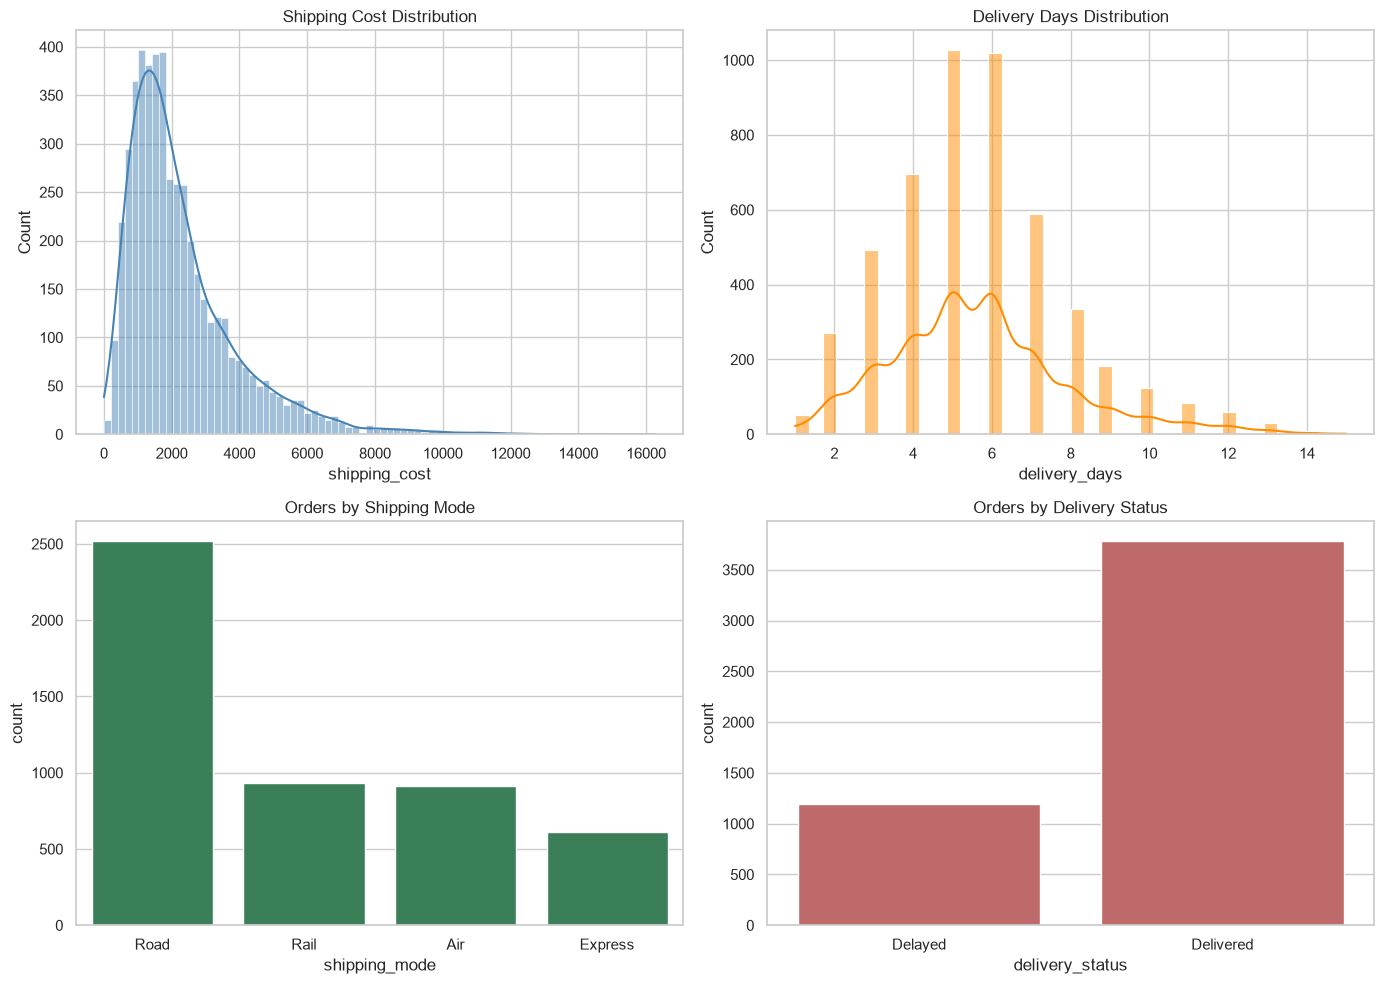

Bivariate analysis: delivery status by shipping mode


delivery_status,Delayed,Delivered
shipping_mode,,
Air,19.21,80.79
Express,17.48,82.52
Rail,28.14,71.86
Road,25.59,74.41


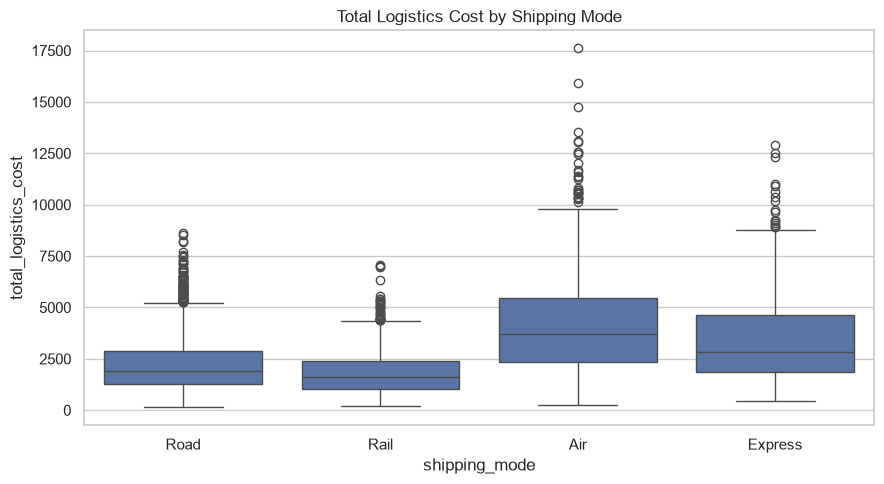

Multivariate analysis: correlation matrix


,distance_km,weight_kg,shipping_cost,fuel_cost,warehouse_processing_hours,delivery_days,delay_days,cost_per_km,total_logistics_cost,on_time_flag
distance_km,1.00,-0.01,0.79,0.94,0.01,0.30,0.06,-0.15,0.84,-0.05
weight_kg,-0.01,1.00,0.01,-0.01,-0.00,-0.00,-0.02,0.08,0.01,0.01
shipping_cost,0.79,0.01,1.00,0.75,0.01,-0.05,0.01,0.36,1.00,-0.00
fuel_cost,0.94,-0.01,0.75,1.00,0.01,0.28,0.05,-0.15,0.80,-0.05
warehouse_processing_hours,0.01,-0.00,0.01,0.01,1.00,0.00,0.00,-0.00,0.01,-0.01
delivery_days,0.30,-0.00,-0.05,0.28,0.00,1.00,0.71,-0.56,-0.01,-0.61
delay_days,0.06,-0.02,0.01,0.05,0.00,0.71,1.00,-0.06,0.02,-0.83
cost_per_km,-0.15,0.08,0.36,-0.15,-0.00,-0.56,-0.06,1.00,0.30,0.08
total_logistics_cost,0.84,0.01,1.00,0.80,0.01,-0.01,0.02,0.30,1.00,-0.01
on_time_flag,-0.05,0.01,-0.00,-0.05,-0.01,-0.61,-0.83,0.08,-0.01,1.00


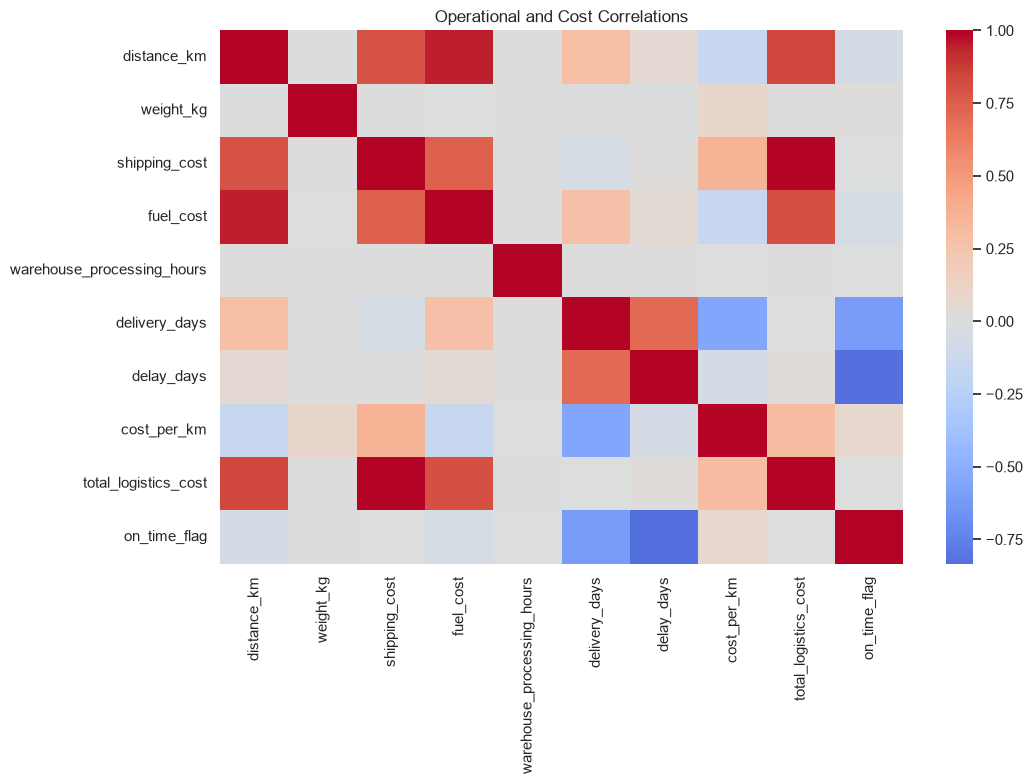

In [7]:
# Section 8 - EDA
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(cleaned_df["shipping_cost"], kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Shipping Cost Distribution")
sns.histplot(cleaned_df["delivery_days"], kde=True, ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Delivery Days Distribution")
sns.countplot(data=cleaned_df, x="shipping_mode", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Orders by Shipping Mode")
sns.countplot(data=cleaned_df, x="delivery_status", ax=axes[1, 1], color="indianred")
axes[1, 1].set_title("Orders by Delivery Status")
plt.tight_layout()
plt.show()

print("Bivariate analysis: delivery status by shipping mode")
display(pd.crosstab(cleaned_df["shipping_mode"], cleaned_df["delivery_status"], normalize="index").mul(100).round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(data=cleaned_df, x="shipping_mode", y="total_logistics_cost")
plt.title("Total Logistics Cost by Shipping Mode")
plt.tight_layout()
plt.show()

print("Multivariate analysis: correlation matrix")
correlation_columns = [
    "distance_km", "weight_kg", "shipping_cost", "fuel_cost",
    "warehouse_processing_hours", "delivery_days", "delay_days",
    "cost_per_km", "total_logistics_cost", "on_time_flag",
]
display(cleaned_df[correlation_columns].corr().round(2))
plt.figure(figsize=(11, 8))
sns.heatmap(cleaned_df[correlation_columns].corr(), cmap="coolwarm", center=0)
plt.title("Operational and Cost Correlations")
plt.tight_layout()
plt.show()

In [8]:
# Section 9 - KPI Analysis
kpis = {
    "Total orders": calculate_total_orders(cleaned_df),
    "Delivered orders": calculate_total_delivered(cleaned_df),
    "Delayed orders": calculate_total_delayed(cleaned_df),
    "On-time delivery percentage": calculate_on_time_percentage(cleaned_df),
    "Average delivery days": calculate_average_delivery_days(cleaned_df),
    "Average delay days": calculate_average_delay_days(cleaned_df),
    "Total shipping cost": calculate_total_shipping_cost(cleaned_df),
    "Average shipping cost": calculate_average_shipping_cost(cleaned_df),
    "Total fuel cost": calculate_total_fuel_cost(cleaned_df),
    "Total logistics cost": calculate_total_logistics_cost(cleaned_df),
    "Average logistics cost per order": calculate_average_logistics_cost(cleaned_df),
    "Average cost per kilometer": calculate_average_cost_per_km(cleaned_df),
    "Average customer rating": calculate_average_customer_rating(cleaned_df),
    "Return rate percentage": calculate_return_rate(cleaned_df),
    "Damage rate percentage": calculate_damage_rate(cleaned_df),
}
kpi_table = pd.Series(kpis, name="value").to_frame()
display(kpi_table)

,value
Total orders,"4,975.00"
Delivered orders,"3,786.00"
Delayed orders,"1,189.00"
On-time delivery percentage,76.10
Average delivery days,5.63
Average delay days,2.95
Total shipping cost,"11,341,047.52"
Average shipping cost,"2,279.61"
Total fuel cost,"1,852,987.35"
Total logistics cost,"13,194,034.87"


In [9]:
# Section 10 - Business Analysis
print("Route performance")
route_performance = analyze_route_performance(cleaned_df).sort_values("avg_delay_days", ascending=False)
display(route_performance.head(10))

print("Warehouse performance")
warehouse_performance = analyze_warehouse_performance(cleaned_df).sort_values("on_time_pct")
display(warehouse_performance)

print("Shipping mode performance")
shipping_mode_analysis = analyze_shipping_mode(cleaned_df).merge(
    analyze_shipping_mode_cost(cleaned_df), on="shipping_mode", how="left"
).merge(
    analyze_shipping_mode_delays(cleaned_df), on="shipping_mode", how="left"
)
display(shipping_mode_analysis.sort_values("delay_pct", ascending=False))

print("Delivery partner performance")
partner_analysis = analyze_delivery_partner(cleaned_df).sort_values("on_time_pct", ascending=False)
display(partner_analysis)

print("Business question answers")
best_route = route_performance.iloc[-1]["route"] if len(route_performance) else "Not available"
most_delayed_route = route_performance.iloc[0]["route"] if len(route_performance) else "Not available"
most_delayed_warehouse = warehouse_performance.iloc[0]["warehouse"] if len(warehouse_performance) else "Not available"
best_partner = partner_analysis.iloc[0]["delivery_partner"] if len(partner_analysis) else "Not available"
most_expensive_mode = shipping_mode_analysis.sort_values("total_logistics_cost", ascending=False).iloc[0]["shipping_mode"] if len(shipping_mode_analysis) else "Not available"
print(f"Most delayed route: {most_delayed_route}")
print(f"Best-performing route by average delay: {best_route}")
print(f"Warehouse with the lowest on-time rate: {most_delayed_warehouse}")
print(f"Highest on-time delivery partner: {best_partner}")
print(f"Shipping mode with the highest average total logistics cost: {most_expensive_mode}")

Route performance


,route,order_count,avg_delay_days,avg_total_cost,avg_cost_per_km
1,Bengaluru -> Bengaluru,1,6.00,"1,428.97",4.72
60,Hyderabad -> Hyderabad,5,1.80,"2,580.25",4.86
51,Delhi -> Surat,42,1.40,"2,300.42",5.58
99,Pune -> Kochi,38,1.29,"2,922.55",5.93
13,Bengaluru -> Nagpur,50,1.24,"3,056.61",6.01
37,Delhi -> Bengaluru,33,1.18,"2,539.45",5.56
28,Chennai -> Kolkata,48,1.17,"2,897.15",5.55
18,Chennai -> Ahmedabad,47,1.15,"2,322.28",5.58
63,Hyderabad -> Kochi,61,1.13,"2,638.13",5.73
42,Delhi -> Hyderabad,38,1.03,"2,500.48",5.71


Warehouse performance


,warehouse,total_orders,avg_processing_hours,on_time_pct
4,Mumbai,740,10.02,73.51
0,Bengaluru,887,8.05,74.30
5,Pune,791,9.01,74.46
2,Delhi,705,9.46,75.74
3,Hyderabad,1087,7.04,78.75
1,Chennai,765,7.50,78.95


Shipping mode performance


,shipping_mode,count,total_logistics_cost,delay_pct
1,Rail,931,"1,846.52",28.14
0,Road,2521,"2,215.73",25.59
2,Air,911,"4,140.13",19.21
3,Express,612,"3,459.80",17.48


Delivery partner performance


,delivery_partner,total_shipments,on_time_pct,avg_cost,damage_rate
0,Blue Dart,799,81.35,"2,270.42",2.13
1,Delhivery,829,78.65,"2,149.94",3.86
4,Shadowfax,841,78.60,"2,338.61",2.14
3,Ecom Express,853,73.74,"2,383.32",2.58
5,Xpressbees,844,73.46,"2,185.17",3.55
2,Dtdc,809,70.95,"2,349.39",2.84


Business question answers
Most delayed route: Bengaluru -> Bengaluru
Best-performing route by average delay: Pune -> Pune
Warehouse with the lowest on-time rate: Mumbai
Highest on-time delivery partner: Blue Dart
Shipping mode with the highest average total logistics cost: Air


c:\Users\HP 440 G8\OneDrive\Documents\python_nit\Logistics Delivery Performance & Cost Analytics\src\visualization.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='delivery_status', ax=ax, palette='Set2')
c:\Users\HP 440 G8\OneDrive\Documents\python_nit\Logistics Delivery Performance & Cost Analytics\src\visualization.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_routes, y='route', x='delay_days', ax=ax, palette='Reds_r')
c:\Users\HP 440 G8\OneDrive\Documents\python_nit\Logistics Delivery Performance & Cost Analytics\src\visualization.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the 

Delivery status


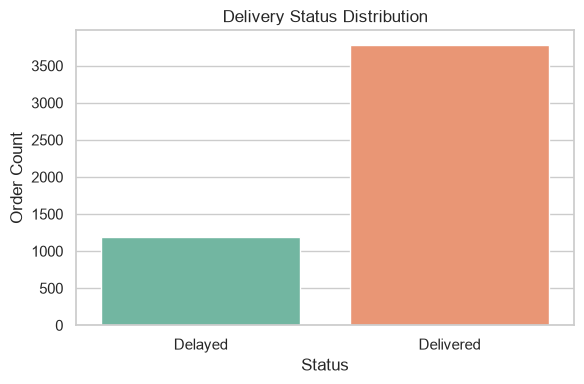

Monthly orders


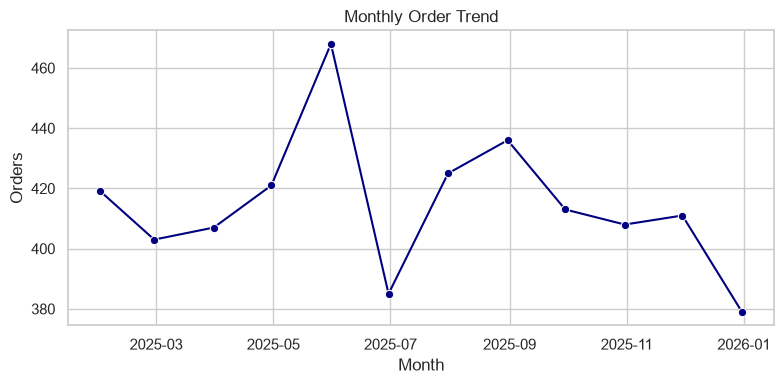

Monthly delivery performance


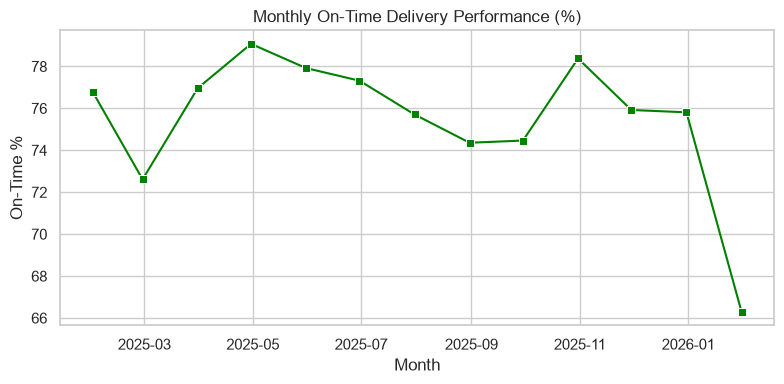

Delay distribution


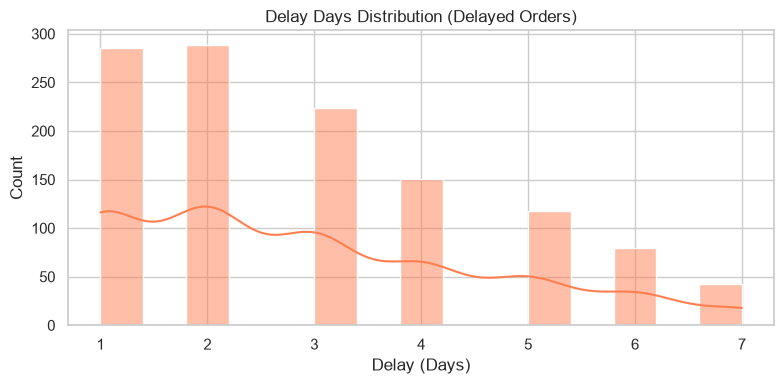

Delay by route


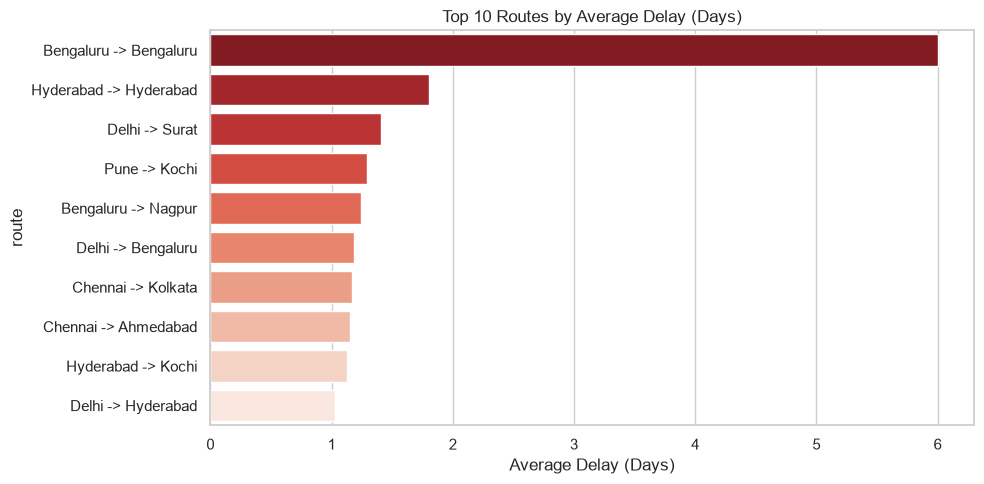

Cost by route


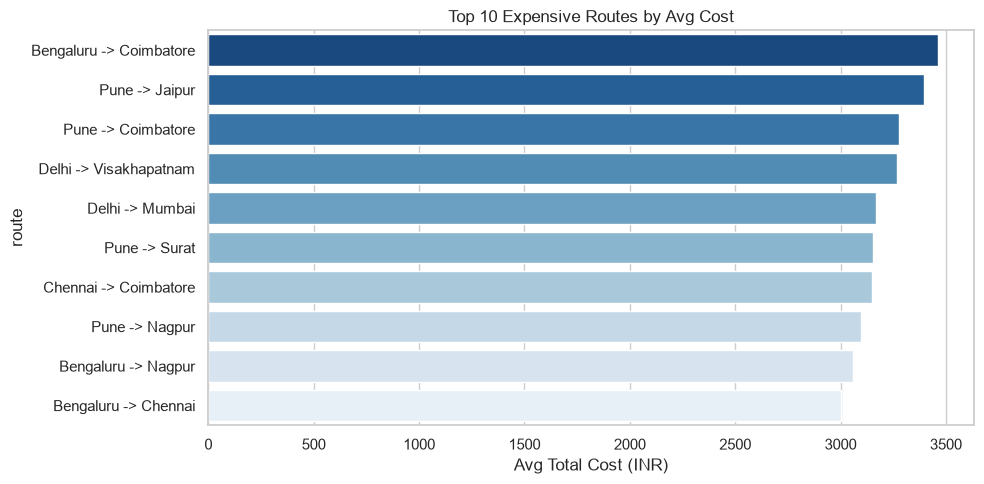

Orders by warehouse


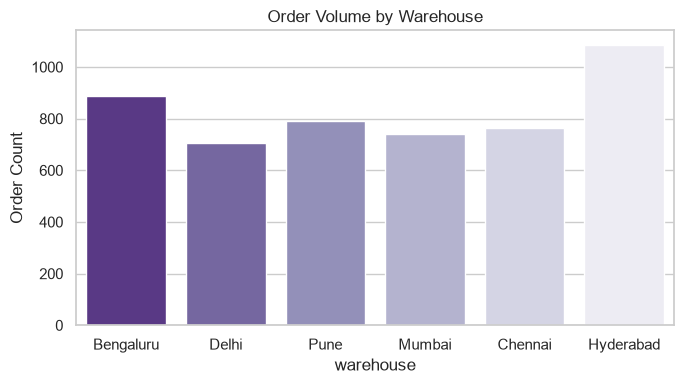

Processing time by warehouse


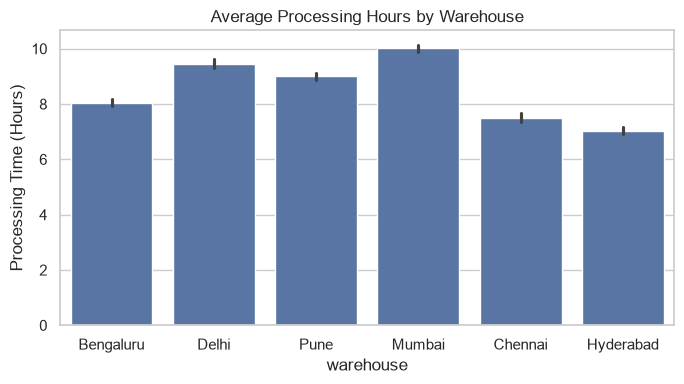

Delay by warehouse


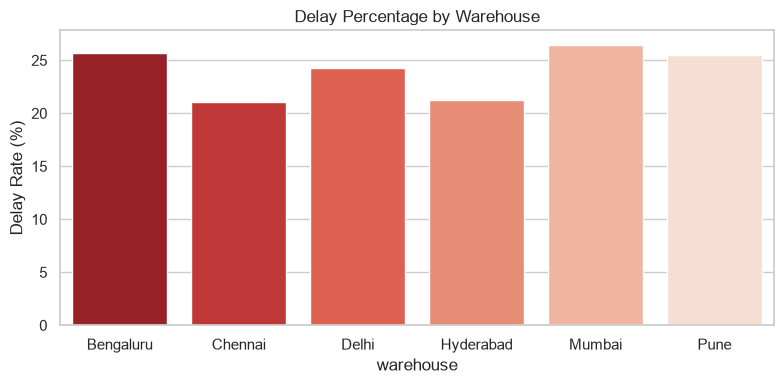

Cost by shipping mode


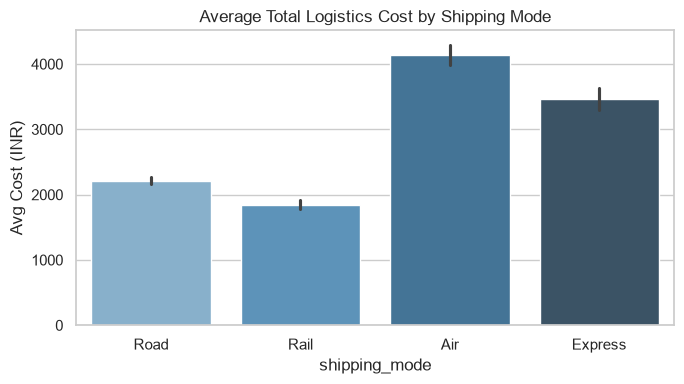

Cost trend


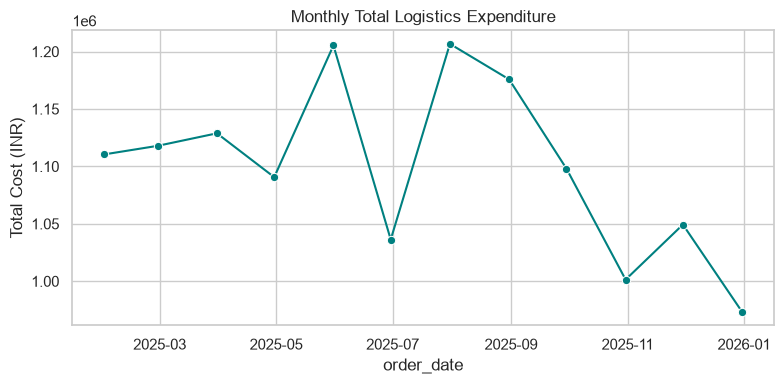

Shipments by partner


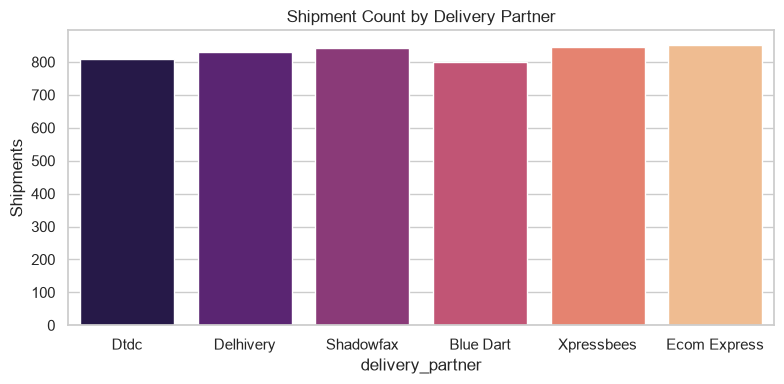

Partner delivery performance


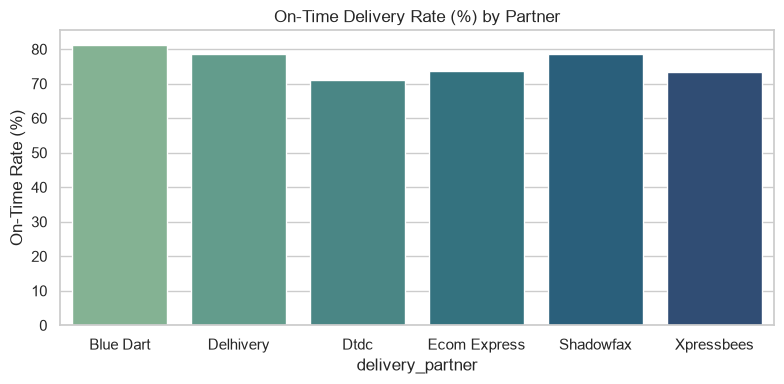

Partner cost


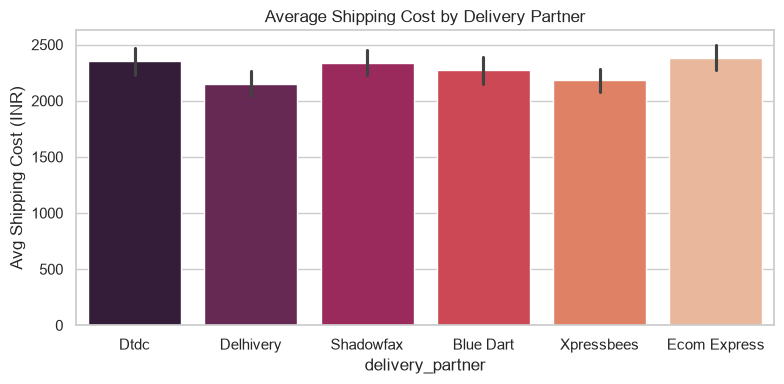

In [10]:
# Section 11 - Visualization
charts = {
    "Delivery status": plot_delivery_status(cleaned_df),
    "Monthly orders": plot_monthly_orders(cleaned_df),
    "Monthly delivery performance": plot_monthly_delivery_performance(cleaned_df),
    "Delay distribution": plot_delay_distribution(cleaned_df),
    "Delay by route": plot_delay_by_route(cleaned_df),
    "Cost by route": plot_cost_by_route(cleaned_df),
    "Orders by warehouse": plot_orders_by_warehouse(cleaned_df),
    "Processing time by warehouse": plot_processing_time_by_warehouse(cleaned_df),
    "Delay by warehouse": plot_delay_by_warehouse(cleaned_df),
    "Cost by shipping mode": plot_cost_by_shipping_mode(cleaned_df),
    "Cost trend": plot_cost_trend(cleaned_df),
    "Shipments by partner": plot_shipments_by_partner(cleaned_df),
    "Partner delivery performance": plot_partner_delivery_performance(cleaned_df),
    "Partner cost": plot_partner_cost(cleaned_df),
}
for chart_title, figure in charts.items():
    print(chart_title)
    display(figure)
    plt.close(figure)

# Section 12 - Business Insights

- Delivery volume and delivery-status results provide the baseline for monitoring service performance.
- The route, warehouse, shipping-mode, and partner tables identify where delay and cost differences are concentrated.
- On-time performance should be reviewed together with average delivery time, delay days, damage rate, and customer rating rather than in isolation.
- Total logistics cost combines shipping and fuel cost, so cost reduction should consider both transport choices and route distance.
- The KPI table and charts provide a repeatable monthly performance-monitoring view.

# Section 13 - Recommendations

1. Prioritize corrective action on the routes and warehouses with the highest average delay and lowest on-time percentage.
2. Compare shipping-mode cost with service performance before changing the transport mix.
3. Use partner-level on-time, cost, damage, and return measures in quarterly carrier reviews.
4. Monitor warehouse processing hours as an early warning indicator for downstream delivery delays.
5. Track shipping cost, fuel cost, total logistics cost, and cost per kilometer together to identify sustainable savings.
6. Refresh the KPI dashboard regularly and investigate material changes from the current baseline.

# Section 14 - Final Conclusion

This project converts raw logistics records into a cleaned, feature-engineered dataset and a structured operational analysis. It measures delivery performance, delay, warehouse activity, route behavior, partner results, and logistics cost. The KPI tables and visualizations provide a practical baseline for management decisions, while the identified problem areas can guide targeted operational improvements and ongoing monitoring.